In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
pd.set_option("display.max_colwidth", 200)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv(
    "/content/IMDB Dataset.csv",
    engine="python"
)

In [ ]:
# df = pd.read_csv("/content/IMDB Dataset.csv")

# print("Dataset shape:", df.shape)
# display(df.head())
# # Q : what's the diffrent between display (df.head()),print(df.head())and df.head()?

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [ ]:
df.duplicated().sum()

np.int64(418)

In [ ]:
df.describe(include='all')

,review,sentiment
count,50000,50000
unique,49582,2
top,"Loved today's show!!! It was a variety and not solely cooking (which would have been great too). Very stimulating and captivating, always keeping the viewer peeking around the corner to see what w...",positive
freq,5,25000


In [ ]:
df.isnull().sum()

,0
review,0
sentiment,0


In [ ]:
print("Unigue atatment lables: ")
print(df['sentiment'].value_counts())

Unigue atatment lables: 
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [ ]:
empty_reviews = df["review"].astype("string").str.strip().eq("").sum()

print("Empty reviews:", empty_reviews)

Empty reviews: 0


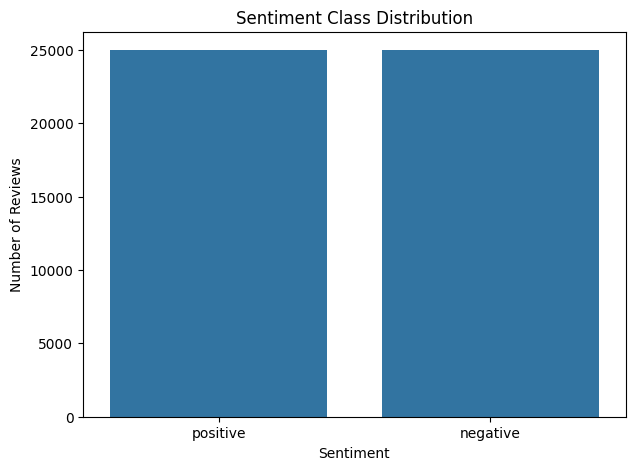

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(data = df,x="sentiment")
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
duplicate_reviews = df[df.duplicated(subset='review',keep=False)]#find reviews appring more than once

In [ ]:
duplicate_reviews

,review,sentiment
42,"Of all the films I have seen, this one, The Rage, has got to be one of the worst yet. The direction, LOGIC, continuity, changes in plot-script and dialog made me cry out in pain. ""How could ANYONE...",negative
84,"We brought this film as a joke for a friend, and could of been our worst joke to play. The film is barely watchable, and the acting is dire. The worst child actor ever used and Hasslehoff giving a...",negative
140,"Before I begin, let me get something off my chest: I'm a huge fan of John Eyres' first film PROJECT: SHADOWCHASER. The film, a B-grade cross of both THE TERMINATOR & DIE HARD, may not be the work ...",negative
219,Ed Wood rides again. The fact that this movie was made should give any young<br /><br />aspiring film maker hope. Any screenplay you might have thought of using to<br /><br />line a litterbox or a...,negative
245,"I have seen this film at least 100 times and I am still excited by it, the acting is perfect and the romance between Joe and Jean keeps me on the edge of my seat, plus I still think Bryan Brown is...",positive
...,...,...
49912,"This is an incredible piece of drama and powerful which hits you. I found the film was great and getting to grips with the two main characters disability, this was represented in a great performan...",positive
49950,"This was a very brief episode that appeared in one of the ""Night Gallery"" show back in 1971. The episode starred Sue Lyon (of Lolita movie fame) and Joseph Campanella who play a baby sitter and a ...",negative
49984,"Hello it is I Derrick Cannon and I welcome you to the first ever Cannonite review show. My movie for this week was debatable, what route what movie, what excellent four star epic would I choose, g...",negative
49986,"This movie is a disgrace to the Major League Franchise. I live in Minnesota and even I can't believe they dumped Cleveland. (Yes I realize at the time the real Indians were pretty good, and the Tw...",negative


In [ ]:
# Check whether identical reviews have different labels
conflicting_reviews = (
    duplicate_reviews
    .groupby("review")["sentiment"]
    .nunique()
)


In [ ]:
conflicting_reviews

,sentiment
review,
"""Go Fish"" garnered Rose Troche rightly or wrongly the reputation of a film maker with much promise.<br /><br />Its then hard to understand how she could turn out a movie made up of stereotypes that one associates with inferior sitcoms. The entire film rings hollow. I cringed the whole way through.<br /><br />Its supposed to be a look into nineties human sexuality. Well not much more here to be learned than from ""In and Out"". By now most of us actually do know, that there are men who are sexually attracted to women and there men who are sexually attracted to men and there are even men sexually attracted to both sexes. <br /><br />Seldom has this revelation been portrayed on the screen with so little wit and style.<br /><br />Pathetic.",1
"""Three"" is a seriously dumb shipwreck movie. Masquerading as a psychological thriller, it's closest relative is the monumentally superior ""Dead Calm"" (also featuring Billy Zane). ""Dead Calm"" provided well drawn characters to root for in the form of Sam Neil and Nicole Kidman's grieving parents attempting to re-define their relationship on an ocean cruise. They end up being terrorised by Zane's adrift psycho-killer. It provided sharp, increasingly ratcheted suspense, a scary feeling of claustrophobia in open seas as the cat and mouse game of life and death unfolded.<br /><br />""Three"" suffers from poorly drawn characterisation (the audience doesn't care what happens to any of them), a stupid and unnecessary voodoo plot device, a total lack of suspense or excitement and some thudding, hammy performances from the principal players. Zane in particular goes way over the top in an irritatingly mannered fashion. In ""Dead Calm"" he was menacing, wired and seething with barely controlled sexual violence. Here he is bombastic, petulant slimy, and unravelled. And where does he get his seemingly inexhaustible supply of dry cigarettes and cigars? And how come his lighter stays full of juice for over a year? Ms Brook is very picturesque, stunningly pretty, but both her chest and rear appear to have been wildly over-inflated by some sort of life-raft pump. They do, however, succeed in acting with more skill and conviction than the rest of her. Dramatic actress, in the purest sense of the term, she is not. The guy playing the voodoo-hexed Manuel, the third component of this sorry triangle, could have been replaced by a lump of driftwood - no one would notice. In fact, judging by his complete lack of ability to deliver dialogue in any meaningful or dynamic way, driftwood represents a potential improvement in the casting stakes (excuse pun).<br /><br />Plus sides: the scenery is nice and the cinematography (above and below the water) is credible.<br /><br />I'm guessing this had a very limited (if any) theatrical release or went straight to rental and retail DVD. The reason for this is it's not very good. If you want something decent along these lines, get ""Dead Calm."" It was made by people who knew a bit about cinema.",1
"""Witchery"" might just be the most incoherent and lamentably scripted horror movie of the 80's but, luckily enough, it has a few compensating qualities like fantastic gore effects, an exhilarating musical score and some terrific casting choices. Honestly the screenplay doesn't make one iota of sense, but who cares when Linda Blair (with an exploded hairstyle) portrays yet another girl possessed by evil powers and David Hasselhof depicts a hunky photographer (who can't seem to get laid) in a movie that constantly features bloody voodoo, sewn-shut lips, upside down crucifixions, vicious burnings and an overused but genuinely creepy tune. Eight random people are gathered together on an abandoned vacation resort island off the coast of Massachusetts. The young couple is there to investigate the place's dark history; the dysfunctional family (with a pregnant Linda Blair even though nobody seems to bother about who the father is and what his whereabouts are) cons

In [ ]:
print("Reviewn eith conflicting sentiment lables: ",
 (conflicting_reviews>1).sum())

Reviewn eith conflicting sentiment lables:  0


In [ ]:
df['char_length'] = df['review'].str.len()

In [ ]:
print(df['char_length'].describe())
# Why are we calculating this?
# Later, when we create sequences for our LSTM, we'll need to decide the maximum sequence length.
# For example, should we retain 200 words? 300 words? 500 words?
# Our EDA will help us make that decision based on actual data rather than guessing.

count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: char_length, dtype: float64


In [ ]:
df['word_count']=df['review'].str.split().str.len()
print(df['word_count'].describe())

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: word_count, dtype: float64


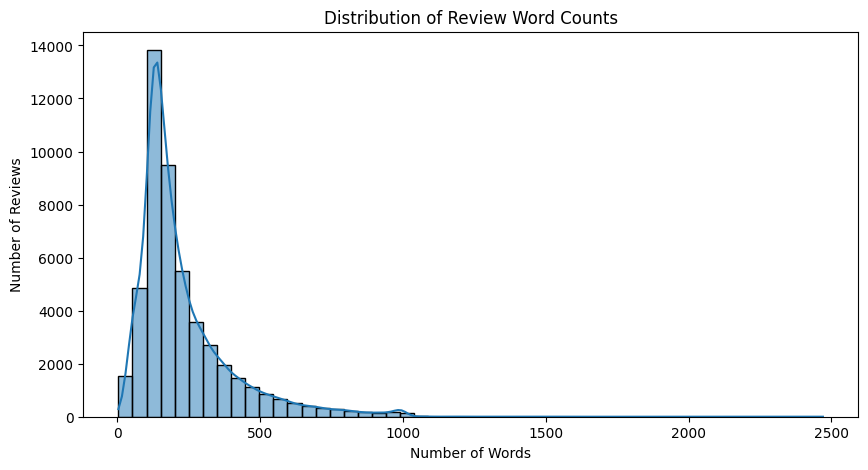

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(data = df,x='word_count',bins=50,kde=True)
plt.title("Distribution of Review Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

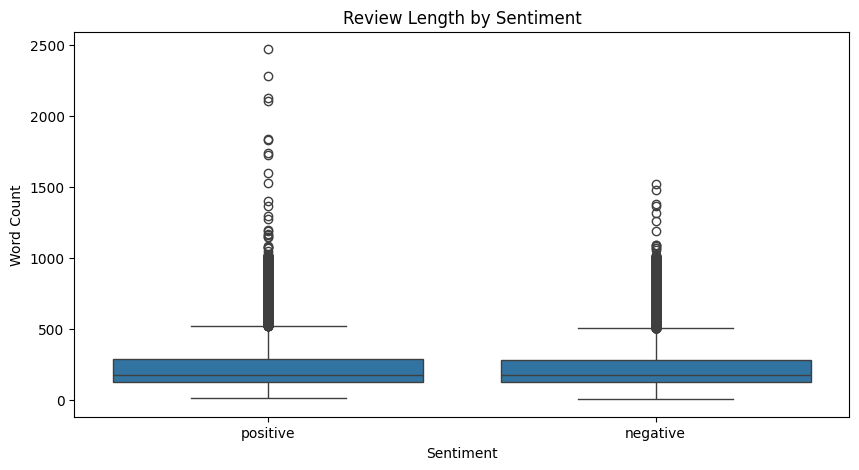

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="word_count"
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Word Count")

plt.show()

In [ ]:
import re

In [ ]:
html_patterns = r"<[^>]+>"
html_reviews = df['review'].str.contains(html_patterns,regex=True,na=False)
print("Reviews contain html patterns :", html_reviews.sum())
print(
    "Percentage:",
    round(html_reviews.mean() * 100, 2),
    "%"
)

Reviews contain html patterns : 29202
Percentage: 58.4 %


In [ ]:
# Calculate percentage of reviews retained
# for different maximum sequence lengths

lengths = [100, 150, 200, 250, 300, 400, 500]

for length in lengths:

    retained = (df["word_count"] <= length).mean() * 100

    truncated = (df["word_count"] > length).mean() * 100

    print(
        f"Length: {length:3d} | "
        f"Retained: {retained:.2f}% | "
        f"Truncated: {truncated:.2f}%"
    )

Length: 100 | Retained: 12.24% | Truncated: 87.76%
Length: 150 | Retained: 39.91% | Truncated: 60.09%
Length: 200 | Retained: 59.14% | Truncated: 40.86%
Length: 250 | Retained: 70.42% | Truncated: 29.58%
Length: 300 | Retained: 77.71% | Truncated: 22.29%
Length: 400 | Retained: 87.03% | Truncated: 12.97%
Length: 500 | Retained: 92.19% | Truncated: 7.81%


In [ ]:
# Display three reviews containing HTML
html_examples = df.loc[html_reviews,'review'].head(3)
for i, review in enumerate(html_examples,1):
  print(f"\nREVIEW {i}")
  print("-"*60)
  print(review[:100])


REVIEW 1
------------------------------------------------------------
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. The

REVIEW 2
------------------------------------------------------------
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-B

REVIEW 3
------------------------------------------------------------
I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air con


In [ ]:
df

,review,sentiment,char_length,word_count
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me...",positive,1761,307
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire p...",positive,998,162
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue i...",positive,926,166
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenl...,negative,748,138
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. This is a movie that seems to be telling us what mone...",positive,1317,230
...,...,...,...,...
49995,"I thought this movie did a down right good job. It wasn't as creative or original as the first, but who was expecting it to be. It was a whole lotta fun. the more i think about it the more i like ...",positive,1008,194
49996,"Bad plot, bad dialogue, bad acting, idiotic directing, the annoying porn groove soundtrack that ran continually over the overacted script, and a crappy copy of the VHS cannot be redeemed by consum...",negative,642,112
49997,"I am a Catholic taught in parochial elementary schools by nuns, taught by Jesuit priests in high school & college. I am still a practicing Catholic but would not be considered a ""good Catholic"" in...",negative,1280,230
49998,"I'm going to have to disagree with the previous comment and side with Maltin on this one. This is a second rate, excessively vicious Western that creaks and groans trying to put across its central...",negative,1234,212


In [ ]:
df["word_count"].max()

2470

In [ ]:
from bs4 import BeautifulSoup

sample = df["review"].iloc[1]

cleaned = BeautifulSoup(sample, "html.parser").get_text(" ")

print("Original:")
print(sample[:300])

print("\nAfter HTML removal:")
print(cleaned[:300])

Original:
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" 

After HTML removal:
A wonderful little production.  The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece.  The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voi


In [ ]:
def clean(text):
  text = BeautifulSoup(text,'html.parser').get_text(" ")# Remove HTML tags
  text = text.lower()# to lower case
  text =re.sub(r"http\S+|www\S+","",text)# Remove URLs
  text = re.sub(r"[^a-zA-Z\s']"," ",text) # Remove unwanted characters while retaining letters & apostrophes
  text = re.sub(r"\s+"," ",text).strip()# Remove extra spaces
  return text


In [ ]:
sample = "This movie isn't good! <br /><br /> Visit www.example.com"

print(clean(sample))

this movie isn't good visit


In [ ]:
df["clean_review"] = df['review'].apply(clean)

positive_reviews = df[ df['sentiment']== "positive"]["clean_review"]
negative_reviews = df[df['sentiment']== "negative"]["clean_review"]

In [ ]:
positive_reviews.head()

,clean_review
0,one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was it...
1,a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomforting sense of realism to the entire piece the actors ...
2,i thought this was a wonderful way to spend time on a too hot summer weekend sitting in the air conditioned theater and watching a light hearted comedy the plot is simplistic but the dialogue is w...
4,petter mattei's love in the time of money is a visually stunning film to watch mr mattei offers us a vivid portrait about human relations this is a movie that seems to be telling us what money pow...
5,probably my all time favorite movie a story of selflessness sacrifice and dedication to a noble cause but it's not preachy or boring it just never gets old despite my having seen it some or more t...


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

In [ ]:
vectorizer = CountVectorizer(stop_words=None,max_features=30)

positive_matrix= vectorizer.fit_transform(positive_reviews)

positive_counts = np.asarray(positive_matrix.sum(axis=0)).flatten()

positive_words = vectorizer.get_feature_names_out()

positive_frequency = pd.DataFrame({"word":positive_words,
                                   "frequency":positive_counts}).sort_values(by="frequency",ascending =False)
display(positive_frequency.head(20))

,word,frequency
23,the,341288
2,and,176633
19,of,152108
25,to,131322
15,is,111834
14,in,99254
16,it,95135
24,this,69648
22,that,69595
4,as,51116


In [ ]:
negative_vectorizer = CountVectorizer(
    stop_words=None,
    max_features=30
)

negative_matrix = negative_vectorizer.fit_transform(
    negative_reviews
)

negative_counts = np.asarray(
    negative_matrix.sum(axis=0)
).flatten()

negative_words = negative_vectorizer.get_feature_names_out()

negative_frequency = pd.DataFrame({
    "word": negative_words,
    "frequency": negative_counts
}).sort_values(
    by="frequency",
    ascending=False
)

display(negative_frequency.head(20))

,word,frequency
23,the,326718
1,and,147812
18,of,137306
26,to,136803
13,is,99258
14,it,95727
12,in,87532
25,this,81354
22,that,74285
27,was,52269


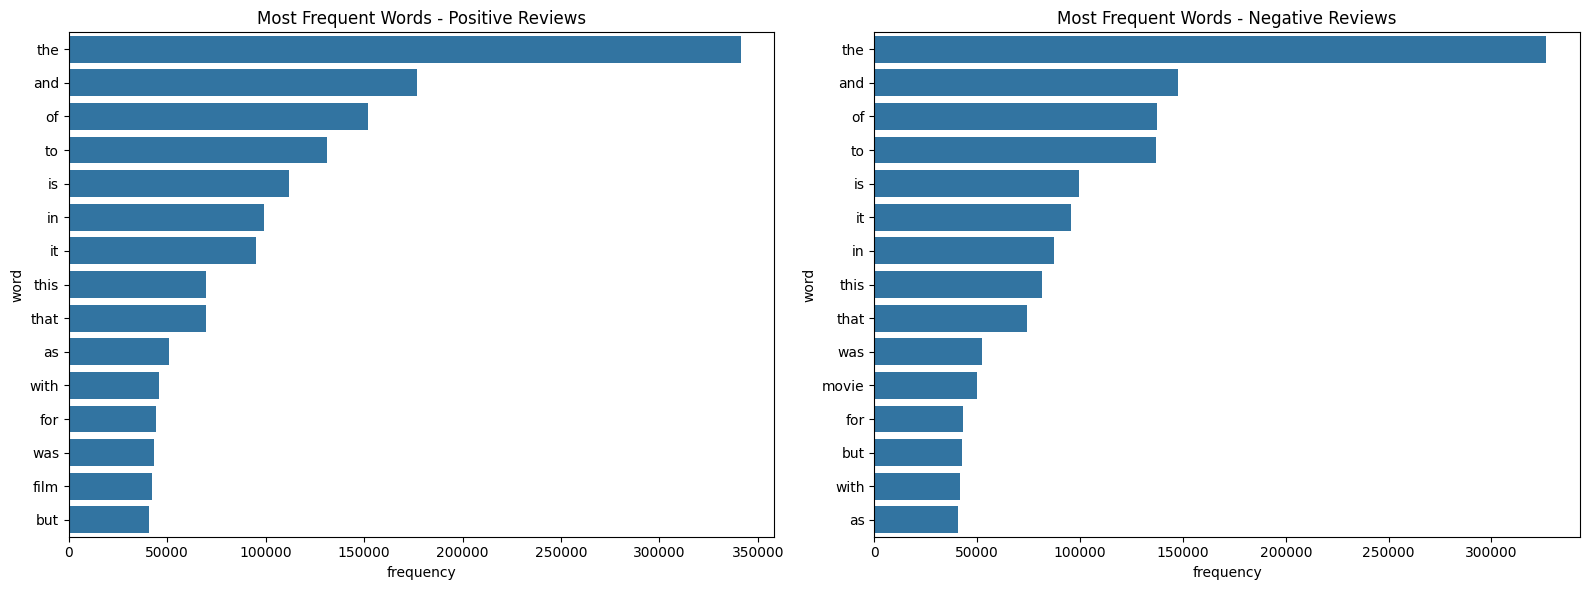

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=positive_frequency.head(15),
    x="frequency",
    y="word",
    ax=axes[0]
)

axes[0].set_title("Most Frequent Words - Positive Reviews")

sns.barplot(
    data=negative_frequency.head(15),
    x="frequency",
    y="word",
    ax=axes[1]
)

axes[1].set_title("Most Frequent Words - Negative Reviews")

plt.tight_layout()
plt.show()

In [ ]:
positive_vectorizer_full = CountVectorizer()

negative_vectorizer_full = CountVectorizer()

positive_matrix_full = positive_vectorizer_full.fit_transform(
    positive_reviews
)

negative_matrix_full = negative_vectorizer_full.fit_transform(
    negative_reviews
)

In [ ]:
# normalized frequency
def calculate_normalized_frequency(matrix, vectorizer):
  counts = np.asarray(matrix.sum(axis = 0)).flatten()
  total_tokens = matrix.sum()
  words = vectorizer.get_feature_names_out()

  frequency_df = pd.DataFrame({"word":words,
                              "count":counts,
                              "frequency_per_10k": counts/total_tokens*10000})

  return frequency_df.sort_values(
        "frequency_per_10k",
        ascending=False
    )


In [ ]:
positive_normalized = calculate_normalized_frequency(
    positive_matrix_full,
    positive_vectorizer_full
)

negative_normalized = calculate_normalized_frequency(
    negative_matrix_full,
    negative_vectorizer_full
)

display(positive_normalized.head(20))
display(negative_normalized.head(20))

,word,count,frequency_per_10k
65688,the,341288,616.533766
2173,and,176633,319.085959
45971,of,152108,274.781762
66482,to,131322,237.232036
33738,is,111834,202.027136
32159,in,99254,179.301477
33842,it,95135,171.860540
65908,this,69648,125.818499
65674,that,69595,125.722755
3379,as,51116,92.340604


,word,count,frequency_per_10k
62897,the,326718,600.515124
2099,and,147812,271.681822
43831,of,137306,252.371555
63622,to,136803,251.447029
32306,is,99258,182.438464
32393,it,95727,175.948406
30748,in,87532,160.885809
63095,this,81354,149.530505
62879,that,74285,136.537522
68553,was,52269,96.071612


In [ ]:
bigram_vectorizer = CountVectorizer(
    ngram_range=(2,2),
    min_df=5,
    max_features = 30
)

positive_bigram_matrix = bigram_vectorizer.fit_transform(
    positive_reviews
)

positive_bigram_counts = np.asarray(
    positive_bigram_matrix.sum(axis=0)
).flatten()

positive_bigrams = pd.DataFrame({
    "bigram": bigram_vectorizer.get_feature_names_out(),
    "frequency": positive_bigram_counts
}).sort_values(
    "frequency",
    ascending=False
)

display(positive_bigrams.head(20))

,bigram,frequency
14,of the,41670
9,in the,25907
20,the film,14716
1,and the,14457
25,this movie,13535
28,to the,12832
12,it is,11555
23,this film,10939
21,the movie,10449
24,this is,10153


In [ ]:
negative_bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    min_df=5,
    max_features=30
)

negative_bigram_matrix = negative_bigram_vectorizer.fit_transform(
    negative_reviews
)

negative_bigram_counts = np.asarray(
    negative_bigram_matrix.sum(axis=0)
).flatten()

negative_bigrams = pd.DataFrame({
    "bigram": negative_bigram_vectorizer.get_feature_names_out(),
    "frequency": negative_bigram_counts
}).sort_values(
    "frequency",
    ascending=False
)

display(negative_bigrams.head(20))

,bigram,frequency
13,of the,35714
7,in the,24609
25,this movie,18024
20,the movie,13530
26,to be,13361
0,and the,12297
18,the film,12233
23,this film,10919
28,to the,10919
11,it was,9226


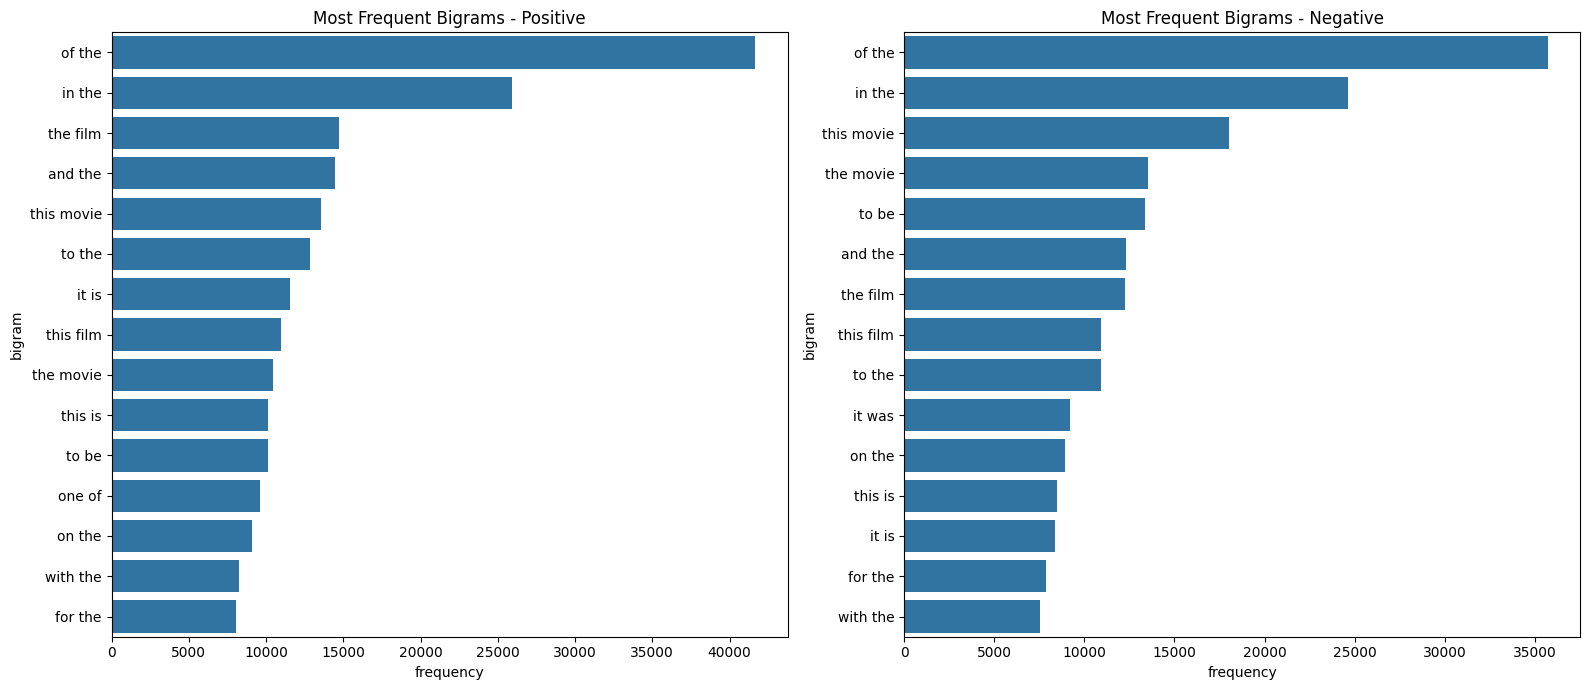

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=positive_bigrams.head(15),
    x="frequency",
    y="bigram",
    ax=axes[0]
)

axes[0].set_title("Most Frequent Bigrams - Positive")

sns.barplot(
    data=negative_bigrams.head(15),
    x="frequency",
    y="bigram",
    ax=axes[1]
)

axes[1].set_title("Most Frequent Bigrams - Negative")

plt.tight_layout()
plt.show()

In [ ]:
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    min_df=5
)

all_bigram_matrix = bigram_vectorizer.fit_transform(
    df["clean_review"]
)

In [ ]:
positive_mask = (
    df["sentiment"] == "positive"
).to_numpy()

negative_mask = (
    df["sentiment"] == "negative"
).to_numpy()

positive_bigram_counts = np.asarray(
    all_bigram_matrix[positive_mask].sum(axis=0)
).flatten()

negative_bigram_counts = np.asarray(
    all_bigram_matrix[negative_mask].sum(axis=0)
).flatten()

bigram_words = bigram_vectorizer.get_feature_names_out()

In [ ]:
positive_total = positive_bigram_counts.sum()
negative_total = negative_bigram_counts.sum()

bigram_comparison = pd.DataFrame({
    "bigram": bigram_words,
    "positive_count": positive_bigram_counts,
    "negative_count": negative_bigram_counts
})

bigram_comparison["positive_rate"] = (
    bigram_comparison["positive_count"] /
    positive_total * 10000
)

bigram_comparison["negative_rate"] = (
    bigram_comparison["negative_count"] /
    negative_total * 10000
)

bigram_comparison["difference"] = (
    bigram_comparison["positive_rate"] -
    bigram_comparison["negative_rate"]
)

In [ ]:
# More common in positive reviews
display(
    bigram_comparison
    .sort_values("difference", ascending=False)
    .head(20)
)

# More common in negative reviews
display(
    bigram_comparison
    .sort_values("difference", ascending=True)
    .head(20)
)

,bigram,positive_count,negative_count,positive_rate,negative_rate,difference
136874,of the,41670,35714,102.964752,88.391035,14.573717
102380,it is,11555,8370,28.551901,20.715489,7.836412
140010,one of,9623,6633,23.778013,16.416468,7.361545
186443,the best,4982,2057,12.310305,5.091011,7.219294
20774,as the,7049,4493,17.417772,11.120035,6.297737
188631,the film,14716,12233,36.362594,30.276293,6.086301
14228,and the,14457,12297,35.722616,30.434691,5.287925
204312,to the,12832,10919,31.707312,27.024184,4.683128
198722,this is,10153,8503,25.087620,21.044660,4.042961
134631,of his,3896,2402,9.626846,5.944875,3.681971


,bigram,positive_count,negative_count,positive_rate,negative_rate,difference
198883,this movie,13535,18024,33.444395,44.608837,-11.164443
194296,the worst,314,3863,0.775880,9.560804,-8.784924
201891,to be,10131,13361,25.033259,33.068058,-8.034799
190729,the movie,10449,13530,25.819023,33.486328,-7.667304
191081,the only,2112,4377,5.218660,10.832938,-5.614278
82769,have been,3316,5330,8.193691,13.191584,-4.997892
21373,at all,1114,2930,2.752645,7.251659,-4.499013
203231,to make,2447,4019,6.046430,9.946900,-3.900469
21574,at least,1698,3225,4.195684,7.981774,-3.786090
185838,the acting,1847,3333,4.563856,8.249071,-3.685215


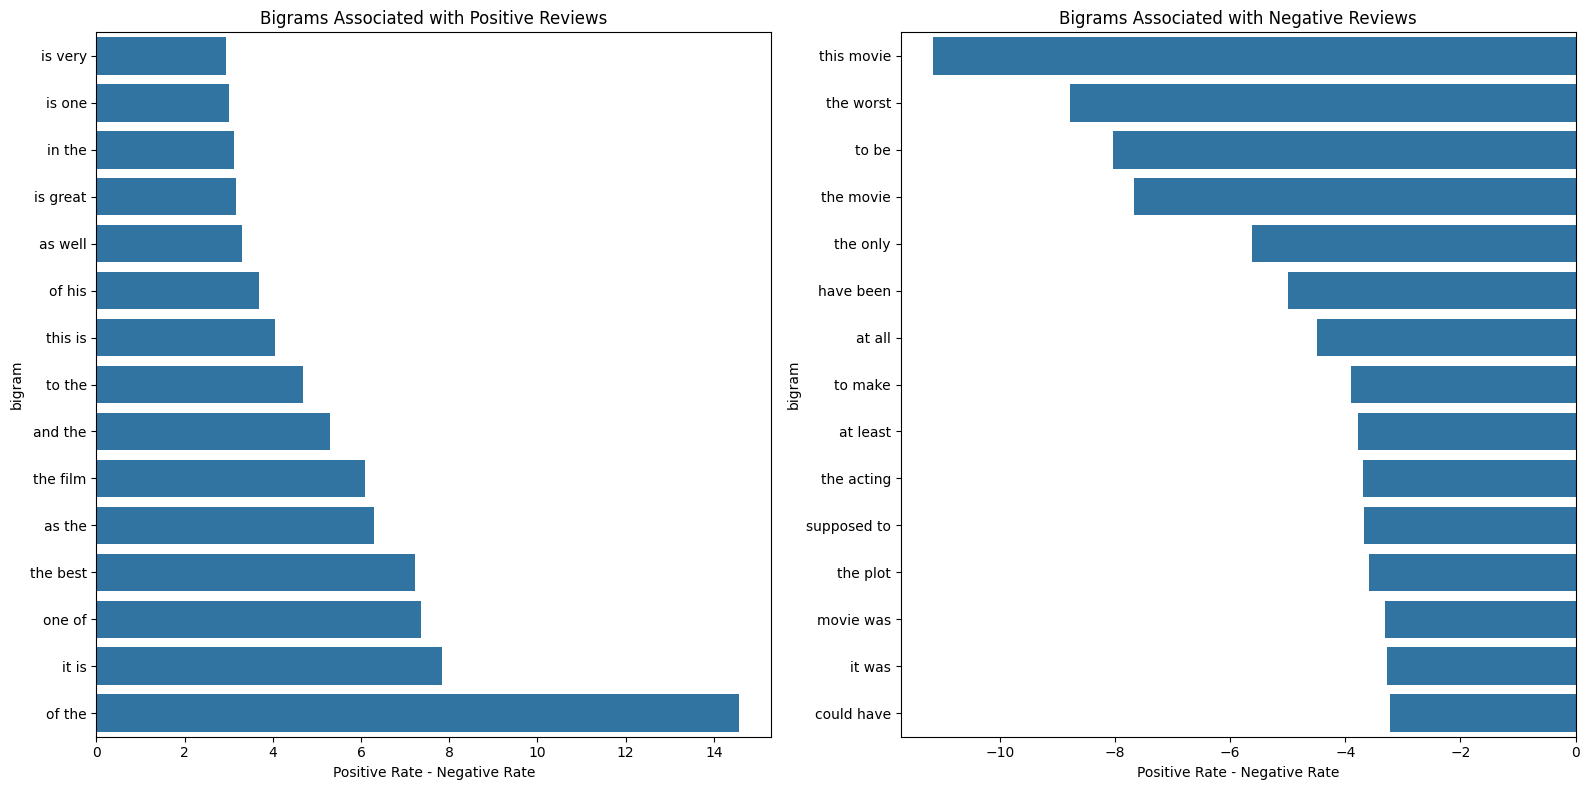

In [ ]:
positive_top = (
    bigram_comparison
    .nlargest(15, "difference")
    .sort_values("difference")
)

negative_top = (
    bigram_comparison
    .nsmallest(15, "difference")
    .sort_values("difference")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

sns.barplot(
    data=positive_top,
    x="difference",
    y="bigram",
    ax=axes[0]
)

axes[0].set_title("Bigrams Associated with Positive Reviews")
axes[0].set_xlabel("Positive Rate - Negative Rate")

sns.barplot(
    data=negative_top,
    x="difference",
    y="bigram",
    ax=axes[1]
)

axes[1].set_title("Bigrams Associated with Negative Reviews")
axes[1].set_xlabel("Positive Rate - Negative Rate")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

sample_reviews = [
    "The movie was excellent and amazing",
    "The movie was terrible and boring",
    "The movie was excellent"
]

tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(sample_reviews)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf.get_feature_names_out()
)

display(tfidf_df.round(3))

,amazing,and,boring,excellent,movie,terrible,the,was
0,0.559,0.425,0.000,0.425,0.330,0.000,0.330,0.330
1,0.000,0.399,0.525,0.000,0.310,0.525,0.310,0.310
2,0.000,0.000,0.000,0.597,0.463,0.000,0.463,0.463
